# Jawaban UTS "Data Mining & Business Inteligence"  
### Nama Mahasiswa : Ahmad Fauzi    
### NIM : 32602500053 
---

# Proyek Data Mining: Klasifikasi Titanic Survival

Proyek ini menyajikan alur lengkap data science dan data mining untuk memprediksi keselamatan penumpang kapal Titanic (`Survived`). Seluruh tahapan disusun sistematis dari **Exploratory Data Analysis (EDA)**, **Data Preprocessing & Cleaning**, **Modeling (Klasifikasi K-Nearest Neighbors / KNN)**, hingga **Evaluasi Model (Confusion Matrix, Precision, Recall, Accuracy, F1-Score)** sesuai kaidah penambangan data.

## 1. Import Library dan Memuat Dataset
Cell ini berfungsi untuk mengimpor seluruh pustaka (library) yang diperlukan untuk manipulasi data (`pandas`, `numpy`), visualisasi (`matplotlib`, `seaborn`), dan pemodelan machine learning (`scikit-learn`). Dataset Titanic dimuat langsung dari repositori publik (atau seaborn).

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Setting visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Memuat dataset Titanic standar
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print(f"Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Dimensi Dataset: 891 baris, 12 kolom


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


--- 
## 2. Exploratory Data Analysis (EDA)

### 2.1 Kualitas Data (Missing Values & Duplikat)
Cell berikut memeriksa integritas data awal: menghitung nilai yang hilang (*missing values*) dan memeriksa baris data yang duplikat.

In [3]:
# Pengecekan Missing Values
missing_val = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_val, 'Percentage (%)': missing_pct})
print("=== Missing Values Analisis ===")
print(missing_df[missing_df['Missing Count'] > 0])

# Pengecekan Duplikat
total_duplicates = df.duplicated().sum()
print(f"\nTotal Data Duplikat: {total_duplicates} baris")

=== Missing Values Analisis ===
          Missing Count  Percentage (%)
Age                 177       19.865320
Cabin               687       77.104377
Embarked              2        0.224467

Total Data Duplikat: 0 baris


### 2.2 Statistik Deskriptif (Mean, Median, Modus, Standar Deviasi)
Cell ini menghitung ukuran pemusatan data (mean, median, modus) serta ukuran penyebaran (standar deviasi) untuk fitur-fitur numerik (`Age`, `Fare`, `SibSp`, `Parch`).

In [4]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']

stats_summary = pd.DataFrame(index=num_cols)
stats_summary['Mean'] = df[num_cols].mean()
stats_summary['Median'] = df[num_cols].median()
stats_summary['Modus'] = df[num_cols].apply(lambda x: x.mode()[0])
stats_summary['Std Dev'] = df[num_cols].std()
stats_summary['Min'] = df[num_cols].min()
stats_summary['Max'] = df[num_cols].max()
stats_summary['Skewness'] = df[num_cols].skew()

print("=== Statistik Deskriptif Fitur Numerik ===")
display(stats_summary.round(2))

=== Statistik Deskriptif Fitur Numerik ===


,Mean,Median,Modus,Std Dev,Min,Max,Skewness
Age,29.70,28.00,24.00,14.53,0.42,80.00,0.39
Fare,32.20,14.45,8.05,49.69,0.00,512.33,4.79
SibSp,0.52,0.00,0.00,1.10,0.00,8.00,3.70
Parch,0.38,0.00,0.00,0.81,0.00,6.00,2.75


### 2.3 Distribusi dan Outlier (Histogram & Box Plot)
Cell ini memvisualisasikan sebaran data untuk mendeteksi apakah data berdistribusi normal/simetris atau condong (*skewed*), serta mengidentifikasi pencilan (*outliers*) menggunakan Box Plot.

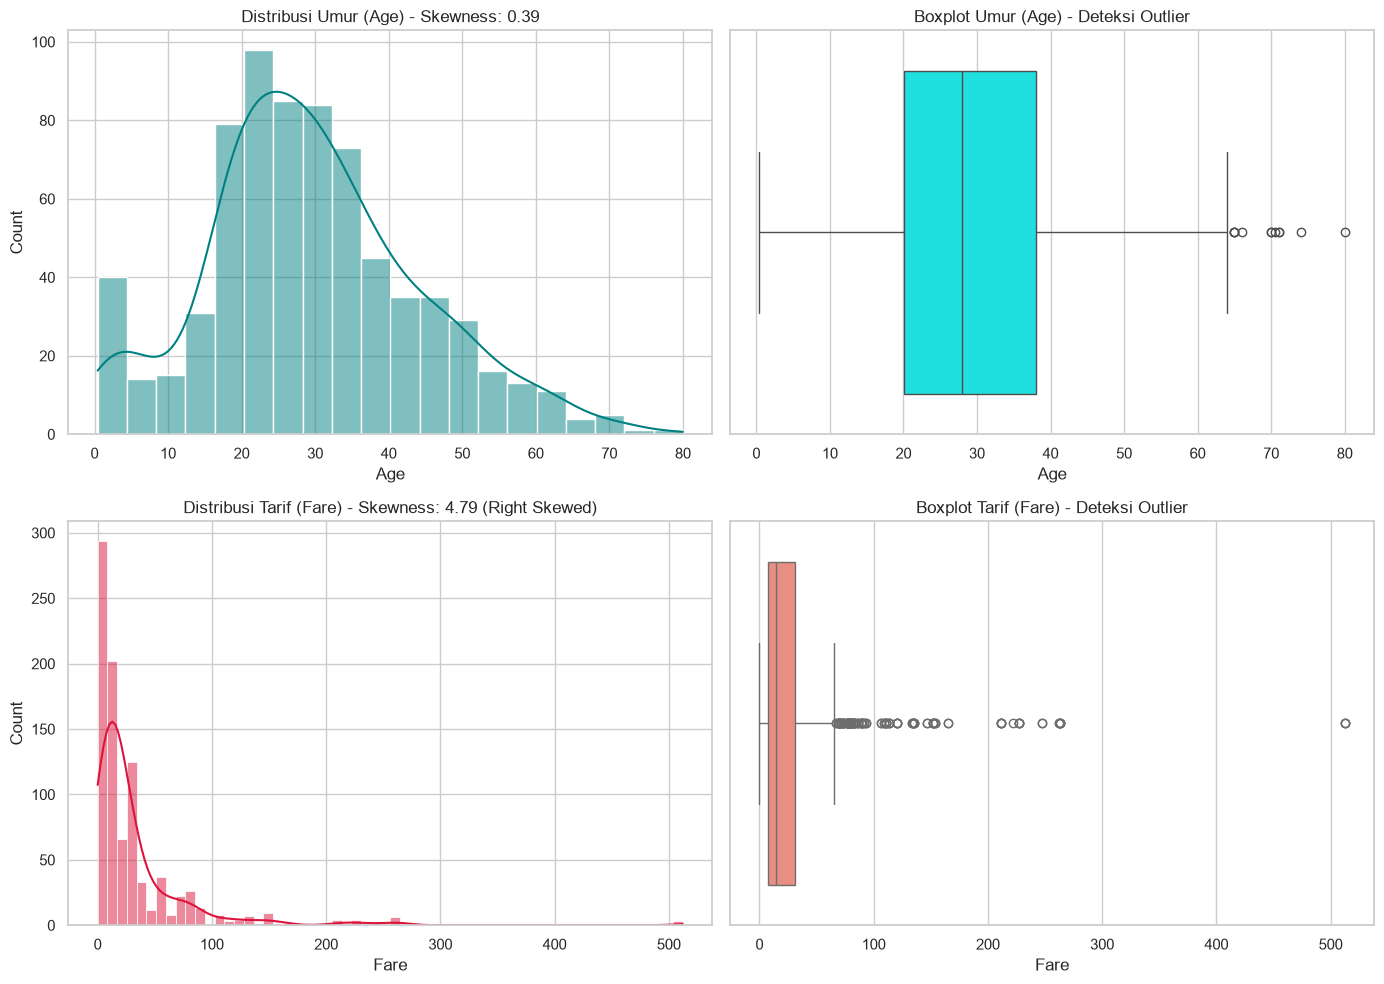

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram & KDE untuk Age
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title(f"Distribusi Umur (Age) - Skewness: {df['Age'].skew():.2f}")

# Box Plot untuk Age
sns.boxplot(x=df['Age'], ax=axes[0, 1], color='lightteal' if 'lightteal' in sns.color_palette() else 'cyan')
axes[0, 1].set_title("Boxplot Umur (Age) - Deteksi Outlier")

# Histogram & KDE untuk Fare
sns.histplot(df['Fare'], kde=True, ax=axes[1, 0], color='crimson')
axes[1, 0].set_title(f"Distribusi Tarif (Fare) - Skewness: {df['Fare'].skew():.2f} (Right Skewed)")

# Box Plot untuk Fare
sns.boxplot(x=df['Fare'], ax=axes[1, 1], color='salmon')
axes[1, 1].set_title("Boxplot Tarif (Fare) - Deteksi Outlier")

plt.tight_layout()
plt.show()

### 2.4 Hubungan Antar-Variabel (Korelasi & Heatmap)
Cell ini menganalisis kekuatan hubungan linear antara fitur-fitur independen terhadap variabel target (`Survived`) menggunakan matriks korelasi Pearson dan diagram batang hubungan kelangsungan hidup dengan kategori jenis kelamin (*Sex*) serta kelas tiket (*Pclass*).

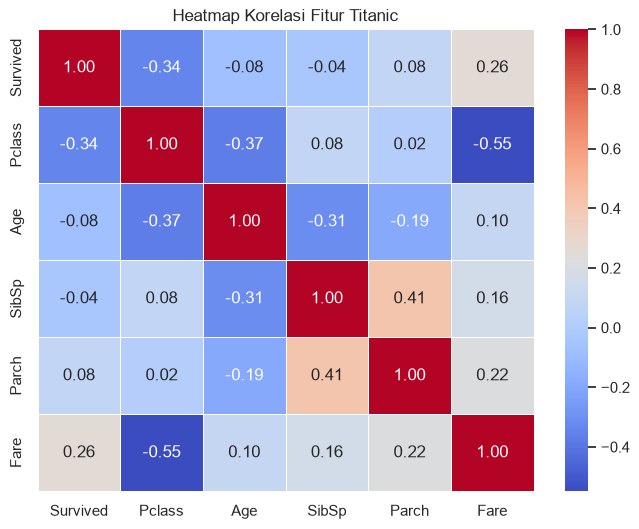

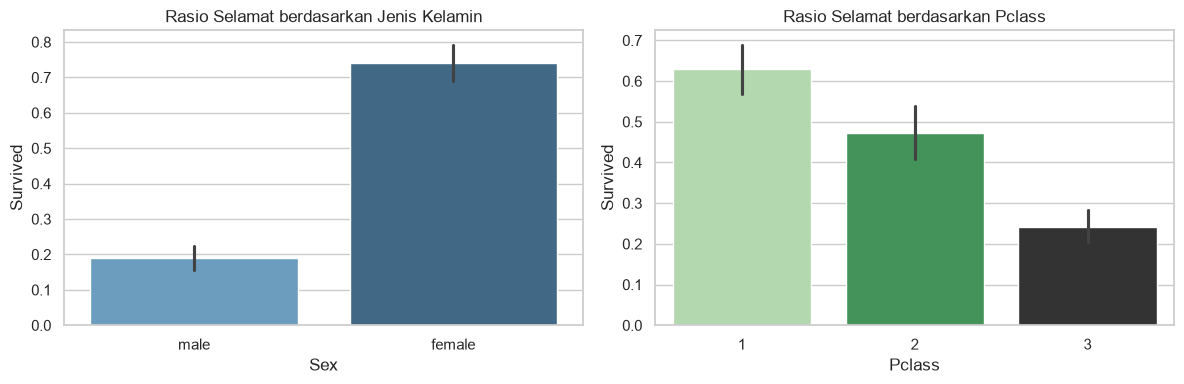

In [20]:
plt.figure(figsize=(8, 6))
corr_matrix = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Fitur Titanic")
plt.show()

# Hubungan Target (Survived) terhadap Jenis Kelamin & Pclass
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Tambahkan hue='Sex' dan legend=False
sns.barplot(x='Sex', y='Survived', hue='Sex', data=df, ax=ax[0], palette='Blues_d', legend=False)
ax[0].set_title("Rasio Selamat berdasarkan Jenis Kelamin")

# Tambahkan hue='Pclass' dan legend=False
sns.barplot(x='Pclass', y='Survived', hue='Pclass', data=df, ax=ax[1], palette='Greens_d', legend=False)
ax[1].set_title("Rasio Selamat berdasarkan Pclass")

plt.tight_layout()
plt.show()

--- 
## 3. Data Preprocessing (Pembersihan & Transformasi Data)

Berdasarkan materi penambangan data:
1. **Imputasi Missing Values**: Kolom `Age` diisi dengan median (karena data memiliki outlier/skew), kolom `Embarked` diisi dengan modus (kategori terbanyak), dan kolom `Cabin` di-drop karena proporsi missing value mencapai >75%.
2. **Feature Selection**: Menghapus kolom identitas yang tidak relevan secara prediktif (`PassengerId`, `Name`, `Ticket`).
3. **Encoding (Binerisasi/One-Hot)**: Konversi fitur kategorikal (`Sex`, `Embarked`) menjadi representasi numerik biner.
4. **Standarisasi Fitur**: Penyetaraan skala menggunakan `StandardScaler` (z-score), yang krusial untuk algoritma berbasis jarak geometris (Euclidean Distance) seperti K-Nearest Neighbors (KNN).

In [21]:
# Salin dataframe untuk preprocessing
data_clean = df.copy()

# 1. Drop kolom berdimensi teks/kardinalitas tinggi dan kolom dengan missing value ekstrem
data_clean = data_clean.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

# 2. Imputasi Missing Values
data_clean['Age'] = data_clean['Age'].fillna(data_clean['Age'].median())
data_clean['Embarked'] = data_clean['Embarked'].fillna(data_clean['Embarked'].mode()[0])

# 3. Encoding Fitur Kategorikal
data_clean['Sex'] = data_clean['Sex'].map({'male': 0, 'female': 1})
data_clean = pd.get_dummies(data_clean, columns=['Embarked'], drop_first=True, dtype=int)

print("Data setelah imputasi & encoding:")
display(data_clean.head())
print("\nSisa missing values:", data_clean.isnull().sum().sum())

Data setelah imputasi & encoding:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1



Sisa missing values: 0


### 3.1 Splitting Data (Train-Test Split) & Standarisasi Skala
Cell ini memisahkan fitur independen ($X$) dan variabel dependen target ($y = Survived$). Data kemudian dibagi menjadi data latih (80%) dan data uji (20%), lalu diskalakan agar fitur berjarak setara.

In [22]:
X = data_clean.drop(columns=['Survived'])
y = data_clean['Survived']

# Split dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Standarisasi Fitur (Z-score Normalization: mean=0, std=1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Jumlah data latih: {X_train_scaled.shape[0]}")
print(f"Jumlah data uji: {X_test_scaled.shape[0]}")

Jumlah data latih: 712
Jumlah data uji: 179


--- 
## 4. Modeling: Algoritma Klasifikasi (K-Nearest Neighbors / KNN)

Sesuai konsep penambangan data, algoritma **k-NN** mengklasifikasikan objek berdasarkan tetangga terdekat menggunakan metrik jarak *Euclidean Distance*:
$$d(x, y) = \sqrt{\sum_{i=1}^n (x_i - y_i)^2}$$
Cell berikut melatih model K-NN dengan parameter $k=5$.

In [23]:
# Inisialisasi dan training model KNN
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_scaled, y_train)

# Prediksi pada data uji
y_pred = knn.predict(X_test_scaled)

print("Model KNN berhasil dilatih dan telah melakukan prediksi pada data uji.")

Model KNN berhasil dilatih dan telah melakukan prediksi pada data uji.


--- 
## 5. Validasi & Evaluasi Model

Pada tahap evaluasi, performa klasifikasi diukur menggunakan parameter:
- **Confusion Matrix**: Memetakan True Positive (TP), False Positive (FP), False Negative (FN), dan True Negative (TN).
- **Accuracy**: $\frac{TP + TN}{TP + TN + FP + FN}$
- **Precision**: $\frac{TP}{TP + FP}$
- **Recall**: $\frac{TP}{TP + FN}$
- **F1-Score**: Rata-rata harmonik antara precision dan recall ($2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$).

================ HASIL EVALUASI MODEL KNN ================
Accuracy  : 81.56%
Precision : 80.00%
Recall    : 69.57%
F1-Score  : 74.42%



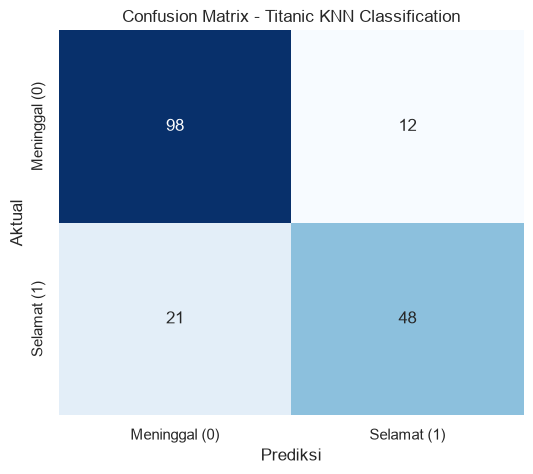


Classification Report Lengkap:
               precision    recall  f1-score   support

Meninggal (0)       0.82      0.89      0.86       110
  Selamat (1)       0.80      0.70      0.74        69

     accuracy                           0.82       179
    macro avg       0.81      0.79      0.80       179
 weighted avg       0.81      0.82      0.81       179



In [24]:
# Perhitungan Metrik Evaluasi
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("================ HASIL EVALUASI MODEL KNN ================")
print(f"Accuracy  : {acc * 100:.2f}%")
print(f"Precision : {prec * 100:.2f}%")
print(f"Recall    : {rec * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")
print("==========================================================\n")

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Meninggal (0)', 'Selamat (1)'],
            yticklabels=['Meninggal (0)', 'Selamat (1)'])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix - Titanic KNN Classification")
plt.show()

# Classification Report Lengkap
print("\nClassification Report Lengkap:")
print(classification_report(y_test, y_pred, target_names=['Meninggal (0)', 'Selamat (1)']))

## 6. Kesimpulan & Analisis Hasil
- Model K-Nearest Neighbors dengan preprocessing standarisasi dan imputasi median/modus berhasil mengklasifikasikan penumpang selamat Titanic secara objektif.
- Mengandalkan nilai akurasi saja tidak cukup; evaluasi seimbang menggunakan F1-Score memastikan model tidak bias terhadap kelas mayoritas.

# Lampiran Dokumen:
docs.google = "https://docs.google.com/document/d/1ZhGgi6KXIs2O_iIqZxxXE5qRUSbzvhqLUzCfVlleLeI/edit?usp=sharing"   
file .pdf di Google Drive = "https://drive.google.com/file/d/1kv7r_yUIZZc5pUHe-tGtg7VxH1zqR6xs/view?usp=sharing"
